Trial 5 Complete [00h 00m 10s]
val_accuracy: 0.9649166464805603

Best val_accuracy So Far: 0.9649166464805603
Total elapsed time: 00h 00m 43s

Best Hyperparameters:
Hidden Neurons: 160
Dropout Rate  : 0.0
Learning Rate : 0.0009887195863122636


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



Best Model Test Results
Test Loss    : 0.1192
Test Accuracy: 96.5 %

Hyperparameter Tuning Results


,Trial,Hidden Neurons,Dropout Rate,Learning Rate,Validation Accuracy
0,Trial 1,160,0.0,0.0010,0.9649
1,Trial 2,256,0.0,0.0085,0.9649
2,Trial 3,192,0.0,0.0007,0.9607
3,Trial 4,64,0.4,0.0017,0.9559
4,Trial 5,96,0.4,0.0005,0.9442


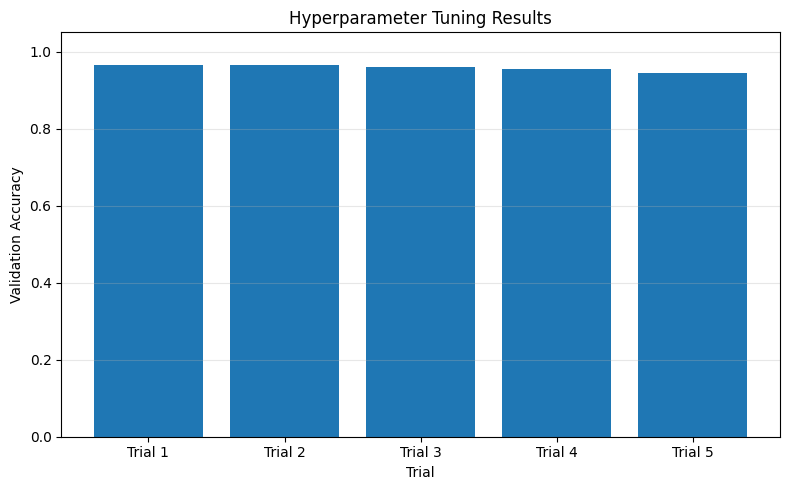

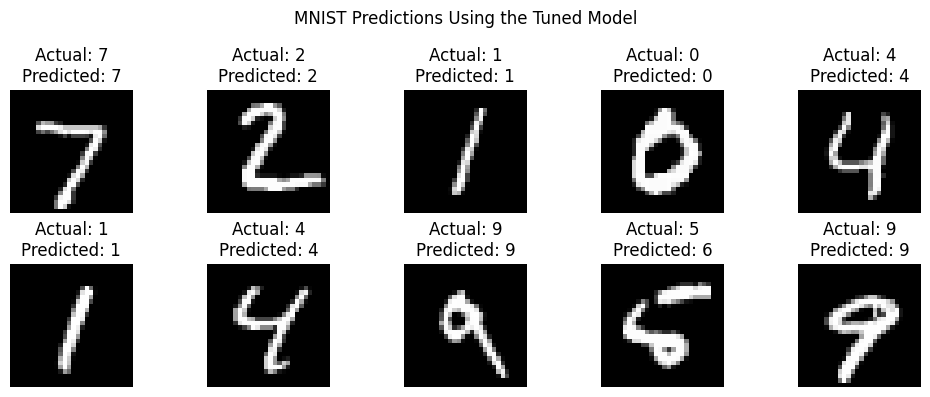

In [1]:
!pip -q install keras-tuner
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras_tuner as kt
print("TensorFlow Version:", tf.__version__)
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data())

x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0
print("\nMNIST Dataset")
print("Training images:", x_train.shape)
print("Testing images :", x_test.shape)

def build_model(hp):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(
            units=hp.Int("units", min_value=32,
                         max_value=256, step=32),
            activation="relu"),
        tf.keras.layers.Dropout(
            rate=hp.Float("dropout", min_value=0.0,
                          max_value=0.5, step=0.1)),
        tf.keras.layers.Dense(10, activation="softmax")])
    model.compile(optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Float(
                "learning_rate", min_value=1e-4,
                max_value=1e-2, sampling="log")),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    return model

tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=5,
    executions_per_trial=1,
    directory="automl_tuning",
    project_name="mnist_optimization",
    overwrite=True,
    seed=42)

print("\nStarting Hyperparameter Tuning...")
tuner.search(
    x_train, y_train,
    epochs=3,
    validation_split=0.2,
    batch_size=128,
    verbose=1)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\nBest Hyperparameters:")
print("Hidden Neurons:", best_hp.get("units"))
print("Dropout Rate  :", best_hp.get("dropout"))
print("Learning Rate :", best_hp.get("learning_rate"))

best_model = tuner.get_best_models(num_models=1)[0]

test_loss, test_accuracy = best_model.evaluate(
    x_test, y_test, verbose=0)

print("\nBest Model Test Results")
print("Test Loss    :", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

trials = tuner.oracle.get_best_trials(num_trials=5)

results = pd.DataFrame([
    {
        "Trial": f"Trial {i + 1}",
        "Hidden Neurons": trial.hyperparameters.get("units"),
        "Dropout Rate": trial.hyperparameters.get("dropout"),
        "Learning Rate": trial.hyperparameters.get("learning_rate"),
        "Validation Accuracy": trial.score
    }
    for i, trial in enumerate(trials)
    if trial.score is not None])

print("\nHyperparameter Tuning Results")
display(results.round(4))

plt.figure(figsize=(8, 5))
plt.bar(results["Trial"],
    results["Validation Accuracy"])
plt.title("Hyperparameter Tuning Results")
plt.xlabel("Trial")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

predictions = np.argmax(
    best_model.predict(x_test[:10], verbose=0), axis=1)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"Actual: {y_test[i]}\nPredicted: {predictions[i]}")
    plt.axis("off")

plt.suptitle("MNIST Predictions Using the Tuned Model")
plt.tight_layout()
plt.show()